In [5]:
import pandas as pd
import matplotlib.pyplot as plt

files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df["order_datetime"] = pd.to_datetime(df["order_datetime"])
df["revenue"] = df["price"] * df["quantity"]
df["order_date"] = df["order_datetime"].dt.date

daily = df.groupby("order_date", as_index=False)["revenue"].sum()
daily["order_date"] = pd.to_datetime(daily["order_date"])

print(daily.head())

  order_date     revenue
0 2024-01-01  4483590.00
1 2024-01-02  4095217.58
2 2024-01-03  4425023.45
3 2024-01-04  3747060.38
4 2024-01-05  4623480.03


In [6]:
daily["revenue_7d"] = daily["revenue"].rolling(7, min_periods=1).mean()

print(daily.head(10))

  order_date     revenue    revenue_7d
0 2024-01-01  4483590.00  4.483590e+06
1 2024-01-02  4095217.58  4.289404e+06
2 2024-01-03  4425023.45  4.334610e+06
3 2024-01-04  3747060.38  4.187723e+06
4 2024-01-05  4623480.03  4.274874e+06
5 2024-01-06  4517551.37  4.315320e+06
6 2024-01-07  3996399.29  4.269760e+06
7 2024-01-08  4189487.36  4.227746e+06
8 2024-01-09  4470895.51  4.281414e+06
9 2024-01-10  4170404.89  4.245040e+06


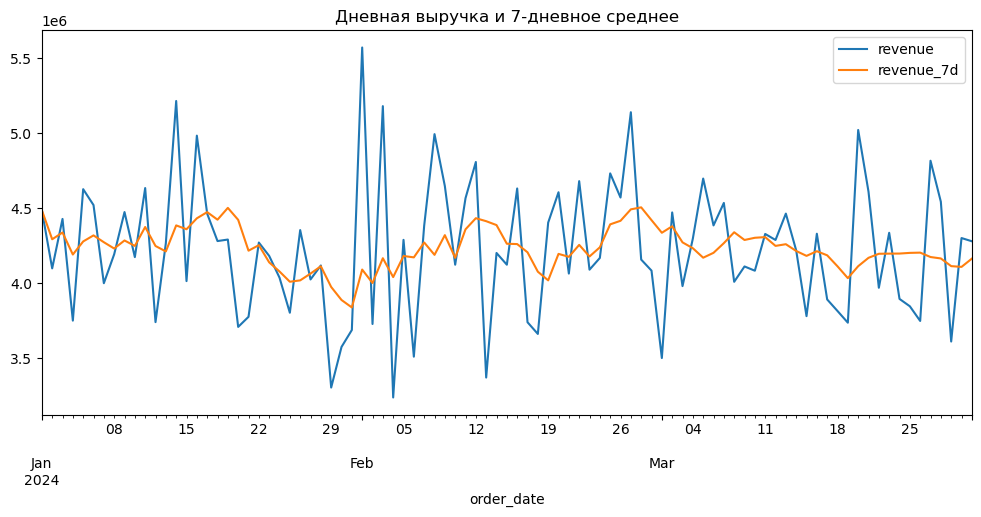

In [7]:
daily.plot(
    x="order_date",
    y=["revenue", "revenue_7d"],
    figsize=(12, 5),
    title="Дневная выручка и 7-дневное среднее"
)
plt.show()

In [8]:
daily["growth"] = daily["revenue_7d"].diff()

max_growth = daily.loc[daily["growth"].idxmax(), ["order_date", "growth"]]
print(max_growth)

order_date    2024-02-01 00:00:00
growth              252677.965714
Name: 31, dtype: object
